# AOG – Exploratory Data Analysis

Data: `datasets/aog_test/` (raw files are read-only; cleaning happens on copies).

**Grain of each table**
- `fleet_info`: 1 row per `aircraft_id`
- `components`: 1 row per `component_id` (each component belongs to one `aircraft_id`)
- `maintenance_events`: 1 row per `event_id` (a maintenance action on one component)
- `sensor_readings`: 1 row per `reading_id`, expected 1 per (`component_id`, `flight_cycle`)

## 1. Load

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

PATH = "datasets/aog_test/"

# fleet_info: aircraft master data
fleet_info = pd.read_csv(PATH + "fleet_info.csv")

# components: components installed on each aircraft
components = pd.read_csv(PATH + "components.csv", parse_dates=["installation_date"])

# maintenance_events: maintenance actions per component
maintenance_events = pd.read_csv(PATH + "maintenance_events.csv", parse_dates=["event_date"])

# sensor_readings: temperature / vibration / pressure per component and flight cycle
sensor_readings = pd.read_csv(PATH + "sensor_readings.csv", parse_dates=["timestamp"])

# tables: name -> DataFrame, used only to loop over the checks below
tables = {
    "fleet_info": fleet_info,
    "components": components,
    "maintenance_events": maintenance_events,
    "sensor_readings": sensor_readings,
}
for name, df in tables.items():
    print(f"{name:20s} {df.shape}")

fleet_info           (20, 5)
components           (50, 5)
maintenance_events   (199, 8)
sensor_readings      (5015, 7)


## 2. Keys and grain

In [2]:
# keys: primary key (pk) and foreign keys (fk) per table
keys = {
    "fleet_info":         {"pk": ["aircraft_id"],  "fk": []},
    "components":         {"pk": ["component_id"], "fk": ["aircraft_id"]},
    "maintenance_events": {"pk": ["event_id"],     "fk": ["component_id", "aircraft_id"]},
    "sensor_readings":    {"pk": ["reading_id"],   "fk": ["component_id"]},
}
for name, k in keys.items():
    is_unique = not tables[name].duplicated(k["pk"]).any()
    print(f"{name:20s} pk={k['pk']} unique={is_unique} fk={k['fk']}")

fleet_info           pk=['aircraft_id'] unique=True fk=[]
components           pk=['component_id'] unique=True fk=['aircraft_id']
maintenance_events   pk=['event_id'] unique=True fk=['component_id', 'aircraft_id']
sensor_readings      pk=['reading_id'] unique=True fk=['component_id']


In [3]:
# components_per_aircraft: unique components installed on each aircraft (0 if none)
components_per_aircraft = (
    components.groupby("aircraft_id")["component_id"].nunique()
    .reindex(fleet_info["aircraft_id"], fill_value=0)
    .sort_values(ascending=False)
)
print(components_per_aircraft.describe())
print("Aircraft with no components:", components_per_aircraft[components_per_aircraft == 0].index.tolist())
components_per_aircraft.to_frame("n_components").T

count    20.000000
mean      2.500000
std       1.670172
min       0.000000
25%       1.000000
50%       2.000000
75%       3.500000
max       5.000000
Name: component_id, dtype: float64
Aircraft with no components: ['AC003']


aircraft_id,AC002,AC018,AC012,AC007,AC016,AC006,AC005,AC015,AC013,AC014,AC004,AC008,AC009,AC001,AC011,AC010,AC019,AC017,AC020,AC003
n_components,5,5,5,5,5,3,3,3,2,2,2,2,2,1,1,1,1,1,1,0


In [4]:
# fan-out: child rows per parent key
print("Events per component:  ", maintenance_events.groupby("component_id").size().describe().round(1).to_dict())
print("Readings per component:", sensor_readings.groupby("component_id").size().describe().round(1).to_dict())

Events per component:   {'count': 51.0, 'mean': 3.9, 'std': 2.0, 'min': 1.0, '25%': 2.5, '50%': 3.0, '75%': 5.5, 'max': 9.0}
Readings per component: {'count': 50.0, 'mean': 100.3, 'std': 0.6, 'min': 100.0, '25%': 100.0, '50%': 100.0, '75%': 100.0, 'max': 102.0}


In [5]:
# orphans: child keys missing in the parent table
print("components.aircraft_id not in fleet_info:   ", (~components["aircraft_id"].isin(fleet_info["aircraft_id"])).sum())
print("events.component_id not in components:      ", (~maintenance_events["component_id"].isin(components["component_id"])).sum())
print("readings.component_id not in components:    ", (~sensor_readings["component_id"].isin(components["component_id"])).sum())
maintenance_events[~maintenance_events["component_id"].isin(components["component_id"])]

components.aircraft_id not in fleet_info:    0
events.component_id not in components:       1
readings.component_id not in components:     0


,event_id,component_id,flight_cycle,maintenance_type,action,downtime_hours,aircraft_id,event_date
28,29,C999,50.0,Scheduled,inspection,2.0,AC001,2024-01-17 12:00:00


In [6]:
# events_check: does the aircraft on the event match the aircraft the component is installed on?
events_check = maintenance_events.merge(
    components[["component_id", "aircraft_id"]], on="component_id",
    how="left", suffixes=("", "_comp"), validate="many_to_one",
)
mismatch = events_check["aircraft_id_comp"].notna() & (events_check["aircraft_id"] != events_check["aircraft_id_comp"])
print("Aircraft mismatches (excluding orphans):", mismatch.sum())

Aircraft mismatches (excluding orphans): 0


## 3. Data quality
### 3.1 Nulls

In [7]:
# nulls: null count and % per column (only columns with nulls)
for name, df in tables.items():
    nulls = df.isna().sum()
    nulls = nulls[nulls > 0]
    print(name, "-> no nulls" if nulls.empty else (nulls.to_frame("n").assign(pct=lambda x: (x["n"] / len(df) * 100).round(1)).to_dict("index")))

fleet_info -> no nulls
components -> no nulls
maintenance_events {'flight_cycle': {'n': 2, 'pct': 1.0}}
sensor_readings {'temperature_celsius': {'n': 100, 'pct': 2.0}, 'vibration_mm_s': {'n': 100, 'pct': 2.0}, 'pressure_psi': {'n': 100, 'pct': 2.0}}


In [8]:
# sensor nulls are scattered: are whole rows empty or single values?
sensor_cols = ["temperature_celsius", "vibration_mm_s", "pressure_psi"]
print(sensor_readings[sensor_cols].isna().sum(axis=1).value_counts().sort_index().rename("n_null_sensors_per_row"))

0    4720
1     290
2       5
Name: n_null_sensors_per_row, dtype: int64


### 3.2 Duplicates

In [9]:
for name, df in tables.items():
    pk = keys[name]["pk"]
    full_dup = df.duplicated().sum()
    dup_no_pk = df.drop(columns=pk).duplicated().sum()   # same content, different id
    print(f"{name:20s} full-row dups={full_dup}  dups ignoring {pk}={dup_no_pk}")

fleet_info           full-row dups=0  dups ignoring ['aircraft_id']=0
components           full-row dups=0  dups ignoring ['component_id']=0
maintenance_events   full-row dups=0  dups ignoring ['event_id']=0
sensor_readings      full-row dups=0  dups ignoring ['reading_id']=15


In [10]:
# sensor_dups: readings repeated for the same (component_id, flight_cycle)
sensor_dups = sensor_readings[sensor_readings.duplicated(["component_id", "flight_cycle"], keep=False)]
print("Rows involved:", len(sensor_dups), "| extra copies:", sensor_readings.duplicated(["component_id", "flight_cycle"]).sum())
sensor_dups.sort_values(["component_id", "flight_cycle"]).head(6)

Rows involved: 30 | extra copies: 15


,reading_id,component_id,flight_cycle,timestamp,temperature_celsius,vibration_mm_s,pressure_psi
88,89,C001,89,2024-01-30 16:27:00,63.512205,2.784834,2038.176891
89,90,C001,89,2024-01-30 16:27:00,63.512205,2.784834,2038.176891
930,931,C010,30,2024-01-11 00:03:00,72.508471,3.923121,2926.234299
931,932,C010,30,2024-01-11 00:03:00,72.508471,3.923121,2926.234299
1132,1133,C012,31,2024-01-11 08:10:00,82.123733,5.752392,25.206772
1133,1134,C012,31,2024-01-11 08:10:00,82.123733,5.752392,25.206772


### 3.3 Labels (categorical values)
`repr` is used so hidden spaces and casing are visible.

In [11]:
label_cols = {
    "fleet_info": ["aircraft_model", "base_airport"],
    "components": ["component_type", "status"],
    "maintenance_events": ["maintenance_type", "action"],
}
for name, cols in label_cols.items():
    for col in cols:
        print(f"{name}.{col}:", tables[name][col].map(repr).value_counts(dropna=False).to_dict())

fleet_info.aircraft_model: {"'B737-800'": 8, "'E190'": 6, "'A320'": 6}
fleet_info.base_airport: {"'LIM'": 8, "'BOG'": 7, "'SCL'": 5}
components.component_type: {"'bearing'": 13, "'filter'": 12, "'actuator'": 11, "'hydraulic_pump'": 10, "'valve'": 4}
components.status: {"'active'": 39, "'replaced'": 11}
maintenance_events.maintenance_type: {"'scheduled'": 68, "'Scheduled'": 60, "'SCHEDULED'": 60, "'UNSCHEDULED '": 4, "'Unscheduled'": 4, "'unscheduled'": 3}
maintenance_events.action: {"'inspection'": 54, "'adjustment'": 48, "'cleaning'": 44, "'lubrication'": 42, "'major_repair'": 7, "'replacement'": 4}


### 3.4 Extreme values and date ranges

In [12]:
for name, df in tables.items():
    print(name)
    display(df.describe().T.round(2))

fleet_info


,count,mean,std,min,25%,50%,75%,max
manufacture_year,20.0,2011.25,4.54,2005.0,2006.75,2011.5,2015.25,2017.0
total_flight_hours,20.0,40654.05,11334.45,18282.0,32349.00,39980.0,48803.00,57031.0


components


,count,mean,min,25%,50%,75%,max
installation_date,50,2022-11-27 02:52:48,2022-01-09 00:00:00,2022-05-25 00:00:00,2022-12-12 12:00:00,2023-06-06 00:00:00,2023-08-12 00:00:00


maintenance_events


,count,mean,min,25%,50%,75%,max,std
event_id,199.0,100.0,1.0,50.5,100.0,149.5,199.0,57.590508
flight_cycle,197.0,52.350254,1.0,28.0,52.0,78.0,100.0,29.710923
downtime_hours,199.0,4.884422,1.0,2.0,3.0,4.0,69.0,8.874075
event_date,199,2024-01-18 14:27:08.140703,2024-01-01 12:00:00,2024-01-10 16:00:00,2024-01-18 12:00:00,2024-01-27 00:00:00,2024-02-03 12:00:00,NaN


sensor_readings


,count,mean,min,25%,50%,75%,max,std
reading_id,5015.0,2508.0,1.0,1254.5,2508.0,3761.5,5015.0,1447.85013
flight_cycle,5015.0,50.489332,1.0,25.0,50.0,75.5,100.0,28.875195
timestamp,5015,2024-01-17 20:24:29.240279,2024-01-01 08:00:00,2024-01-09 08:57:00,2024-01-17 16:58:00,2024-01-26 04:31:00,2024-02-03 08:59:00,NaN
temperature_celsius,4915.0,66.332193,40.673972,53.341546,61.867469,81.304373,999.0,27.746541
vibration_mm_s,4915.0,3.625134,1.135324,1.915628,3.240888,5.350224,12.878718,1.816944
pressure_psi,4915.0,1230.744697,-1.0,25.846074,314.30179,2030.861573,3177.153871,1160.223232


In [13]:
# date ranges
print("installation_date:", components["installation_date"].min().date(), "->", components["installation_date"].max().date())
print("event_date:       ", maintenance_events["event_date"].min(), "->", maintenance_events["event_date"].max())
print("timestamp:        ", sensor_readings["timestamp"].min(), "->", sensor_readings["timestamp"].max())

installation_date: 2022-01-09 -> 2023-08-12
event_date:        2024-01-01 12:00:00 -> 2024-02-03 12:00:00
timestamp:         2024-01-01 08:00:00 -> 2024-02-03 08:59:00


In [14]:
# sentinels: physically impossible values that look like placeholder codes
print("temperature_celsius == 999:", (sensor_readings["temperature_celsius"] == 999).sum())
print("pressure_psi < 0:          ", (sensor_readings["pressure_psi"] < 0).sum())

temperature_celsius == 999: 3
pressure_psi < 0:           3


In [15]:
# downtime: long downtimes - check they are unscheduled repairs, not errors
maintenance_events.nlargest(8, "downtime_hours")[["event_id", "component_id", "maintenance_type", "action", "downtime_hours"]]

,event_id,component_id,maintenance_type,action,downtime_hours
125,126,C038,unscheduled,replacement,69.0
53,54,C003,Unscheduled,replacement,59.0
175,176,C022,UNSCHEDULED,major_repair,50.0
118,119,C004,Unscheduled,replacement,46.0
159,160,C030,unscheduled,major_repair,37.0
97,98,C040,Unscheduled,major_repair,35.0
26,27,C047,UNSCHEDULED,major_repair,31.0
4,5,C012,UNSCHEDULED,replacement,30.0


## 4. Sensor scales
The three sensors use different units, and pressure also changes a lot **by component type**
(bearings ~25 psi vs hydraulic pumps ~3000 psi). A global scale would hide the signal inside each type,
so readings are standardized **within `component_type`** (z-score).

In [16]:
# sensor_clean: sentinels -> NaN and duplicate (component, cycle) rows removed; raw table untouched
sensor_clean = sensor_readings.copy()
sensor_clean.loc[sensor_clean["temperature_celsius"] == 999, "temperature_celsius"] = float("nan")
sensor_clean.loc[sensor_clean["pressure_psi"] < 0, "pressure_psi"] = float("nan")
sensor_clean = sensor_clean.drop_duplicates(["component_id", "flight_cycle"])

# add component_type to each reading
sensor_clean = sensor_clean.merge(components[["component_id", "component_type"]],
                                  on="component_id", how="left", validate="many_to_one")
print(len(sensor_readings), "->", len(sensor_clean), "rows")
sensor_clean.groupby("component_type")[sensor_cols].median().round(1)

5015 -> 5000 rows


,temperature_celsius,vibration_mm_s,pressure_psi
component_type,,,
actuator,60.1,3.0,1999.0
bearing,85.1,6.0,25.0
filter,45.2,1.5,299.4
hydraulic_pump,75.0,4.0,2998.7
valve,55.1,2.0,1500.1


In [17]:
# z-score within component_type: 0 = typical for that type, +/-3 = extreme
for col in sensor_cols:
    by_type = sensor_clean.groupby("component_type")[col]
    sensor_clean[col + "_z"] = (sensor_clean[col] - by_type.transform("mean")) / by_type.transform("std")

z_cols = [c + "_z" for c in sensor_cols]
sensor_clean[z_cols].describe().round(2)

,temperature_celsius_z,vibration_mm_s_z,pressure_psi_z
count,4897.00,4900.00,4897.00
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-3.51,-2.64,-5.78
25%,-0.62,-0.50,-0.56
50%,-0.07,-0.16,0.06
75%,0.51,0.25,0.66
max,6.09,8.01,2.84


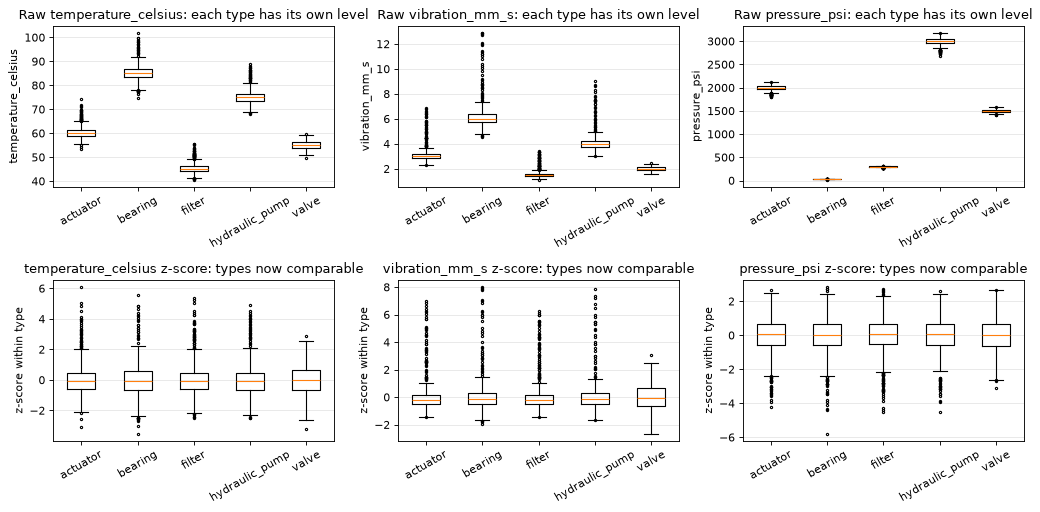

In [18]:
types = sorted(sensor_clean["component_type"].unique())
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), dpi=80)

for i, col in enumerate(sensor_cols):
    raw = [sensor_clean.loc[sensor_clean["component_type"] == t, col].dropna() for t in types]
    std = [sensor_clean.loc[sensor_clean["component_type"] == t, col + "_z"].dropna() for t in types]
    axes[0, i].boxplot(raw, tick_labels=types, flierprops={"markersize": 2})
    axes[0, i].set_title(f"Raw {col}: each type has its own level")
    axes[1, i].boxplot(std, tick_labels=types, flierprops={"markersize": 2})
    axes[1, i].set_title(f"{col} z-score: types now comparable")
    axes[1, i].set_ylabel("z-score within type")
    axes[0, i].set_ylabel(col)
    for ax in axes[:, i]:
        ax.tick_params(axis="x", rotation=30)
        ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# readings beyond 3 std of their component type
print((sensor_clean[z_cols].abs() > 3).sum())

temperature_celsius_z     82
vibration_mm_s_z         114
pressure_psi_z            59
dtype: int64


## 5. Unify `maintenance_type`
The 6 raw values are the same 2 labels written with different casing and a trailing space
(`'unscheduled '`). Fix: `strip()` + `lower()`.

In [20]:
# events_clean: maintenance_events with unified maintenance_type
events_clean = maintenance_events.copy()
events_clean["maintenance_type"] = events_clean["maintenance_type"].str.strip().str.lower()

print(maintenance_events["maintenance_type"].map(repr).value_counts().to_dict())
print(events_clean["maintenance_type"].value_counts().to_dict())
assert set(events_clean["maintenance_type"]) == {"scheduled", "unscheduled"}

{"'scheduled'": 68, "'Scheduled'": 60, "'SCHEDULED'": 60, "'UNSCHEDULED '": 4, "'Unscheduled'": 4, "'unscheduled'": 3}
{'scheduled': 188, 'unscheduled': 11}


In [21]:
# sanity check: routine actions should be scheduled, repairs/replacements unscheduled
pd.crosstab(events_clean["action"], events_clean["maintenance_type"])

maintenance_type,scheduled,unscheduled
action,,
adjustment,48,0
cleaning,44,0
inspection,54,0
lubrication,42,0
major_repair,0,7
replacement,0,4


In [22]:
# downtime by maintenance type
events_clean.groupby("maintenance_type")["downtime_hours"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
maintenance_type,,,,,,,,
scheduled,188.0,3.0,1.4,1.0,2.0,3.0,4.0,5.0
unscheduled,11.0,36.8,18.3,10.0,28.5,35.0,48.0,69.0


## 6. Findings

| # | Table | Issue | Count | Decision |
|---|---|---|---|---|
| 1 | maintenance_events | `maintenance_type` has 6 spellings of 2 labels (casing + trailing space) | 199 rows | `strip().lower()` → `scheduled` / `unscheduled` |
| 2 | maintenance_events | `component_id = C999` not in components (orphan) | 1 | Keep, flag; drop when joining to components |
| 3 | maintenance_events | `flight_cycle` null | 2 | Keep as NaN |
| 4 | maintenance_events | Downtime up to 69 h | 8 events ≥ 30 h | Valid: all unscheduled repairs/replacements |
| 5 | sensor_readings | Duplicate (component, cycle) rows with new `reading_id` | 15 | Drop duplicates |
| 6 | sensor_readings | `temperature_celsius = 999` sentinel | 3 | Set to NaN |
| 7 | sensor_readings | `pressure_psi = -1` sentinel | 3 | Set to NaN |
| 8 | sensor_readings | ~100 nulls per sensor, scattered (not whole rows) | ~2% each | Keep as NaN |
| 9 | sensor_readings | Sensor scales differ by unit and by component type | – | z-score within `component_type` |
| 10 | sensor_readings | Readings beyond 3 std of their component type (temp / vib / pressure) | 82 / 114 / 59 | Keep: plausible degradation signal, not errors |
| 11 | maintenance_events | Only 11 of 199 events are unscheduled | 5.5% | Strong imbalance if used as a target |
| 12 | fleet_info | `AC003` has no components | 1 aircraft | Keep; no sensor/event data for it |
| 13 | sensor_readings | Short window: 2024-01-01 → 2024-02-03 | ~1 month | Limits time-based validation later |